# Logistic Regression from Scratch + Regularisasi (L1, L2, Elastic Net)

Prediksi pembatalan booking (`is_canceled`). Semua bagian inti (preprocessing, split, model, optimisasi, metrik) diimplementasikan dengan **NumPy/Pandas saja**, tanpa scikit-learn.

Fungsi objektif yang diminimalkan:

$$J(w,b) = \underbrace{-\frac{1}{n}\sum_i \big[y_i\log p_i + (1-y_i)\log(1-p_i)\big]}_{\text{log-loss}} + R(w), \quad p_i = \sigma(w^\top x_i + b)$$

| Regularisasi | $R(w)$ |
|---|---|
| Tanpa | $0$ |
| L1 (Lasso) | $\lambda \lVert w \rVert_1$ |
| L2 (Ridge) | $\frac{\lambda}{2} \lVert w \rVert_2^2$ |
| Elastic Net | $\lambda\big[\alpha \lVert w \rVert_1 + \frac{1-\alpha}{2}\lVert w \rVert_2^2\big]$ |

Bias $b$ tidak diregularisasi. Bagian L2 masuk ke gradien, sedangkan bagian L1 (yang tidak differentiable di 0) ditangani dengan **proximal step / soft-thresholding**, sehingga bobot benar-benar bisa menjadi 0.

Nilai log-loss validasi setiap model disimpan pada variabel **`log_uniconilear`**.

**Lokasi & cara menjalankan.** Notebook ini berada di `notebooks/` dan dijalankan dari folder tersebut. Data dibaca dari `../data/`; *submission* (`submission_logreg.csv`) dan video ditulis ke `../output/`; model `.pkl` ditulis ke `../models/`. Selain `requirements.txt`, bagian video membutuhkan `ffmpeg` (misalnya `pip install imageio-ffmpeg`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)

DATA_DIR = '../data'      # train.csv, test.csv, sample_submission.csv
OUTPUT_DIR = '../output'  # submission & video
TARGET = 'is_canceled'

## 1. Load Data

In [2]:
train = pd.read_csv(f'{DATA_DIR}/train.csv', dtype={'id': str})
test = pd.read_csv(f'{DATA_DIR}/test.csv', dtype={'id': str})

print('train:', train.shape, '| test:', test.shape)
print('\nDistribusi target:')
print(train[TARGET].value_counts(normalize=True))
train.head()

train: (27373, 19) | test: (6844, 18)

Distribusi target:
is_canceled
0    0.672341
1    0.327659
Name: proportion, dtype: float64


,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


In [3]:
pd.DataFrame({
    'missing_train': train.isna().sum(),
    'missing_test': test.isna().sum(),
})

,missing_train,missing_test
arrival_day,0,0.0
arrival_month,0,0.0
arrival_year,0,0.0
booking_channel,0,0.0
days_before_arrival,1123,290.0
id,0,0.0
is_canceled,0,NaN
is_returning_guest,0,0.0
meal_package,1760,442.0
needs_parking,1082,247.0


## 2. Preprocessing (from scratch)

- Missing value numerik diisi **median**, kategorikal diisi **modus** (dihitung dari data train saja). Kolom yang punya missing value diberi indikator `*_was_missing`.
- Feature engineering: total malam, total tamu, flag menginap gratis, log lead time, log harga, encoding siklik bulan.
- One-hot encoding untuk `meal_package`, `room_category`, `booking_channel`.
- Standardisasi (z-score) memakai mean/std data train, supaya gradient descent stabil dan regularisasi adil antar fitur.

In [4]:
CAT_COLS = ['meal_package', 'room_category', 'booking_channel']


def add_features(df):
    df = df.copy()
    df['total_nights'] = df['weekend_nights'] + df['weekday_nights']
    df['total_guests'] = df['num_adults'] + df['num_children']
    df['is_free_stay'] = (df['nightly_rate_idr'] == 0).astype(float)
    df['log_lead_time'] = np.log1p(df['days_before_arrival'].clip(lower=0))
    df['log_rate'] = np.log1p(df['nightly_rate_idr'].clip(lower=0))
    df['rate_per_guest'] = df['nightly_rate_idr'] / df['total_guests'].clip(lower=1)
    df['month_sin'] = np.sin(2 * np.pi * df['arrival_month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['arrival_month'] / 12)
    return df


class Preprocessor:
    def fit(self, df):
        drop = set(CAT_COLS) | {'id', TARGET}
        self.num_cols = [c for c in df.columns if c not in drop]
        self.missing_cols = [c for c in self.num_cols if df[c].isna().any()]
        self.medians = df[self.num_cols].median()
        self.modes = {c: df[c].mode()[0] for c in CAT_COLS}
        self.categories = {c: sorted(df[c].dropna().unique()) for c in CAT_COLS}

        X = self._build(df)
        self.feature_names = X.columns.tolist()
        self.mean = X.mean()
        self.std = X.std().replace(0, 1.0)
        return self

    def _build(self, df):
        df = df.copy()
        for c in self.missing_cols:
            df[f'{c}_was_missing'] = df[c].isna().astype(float)
        df[self.num_cols] = df[self.num_cols].fillna(self.medians)
        for c in CAT_COLS:
            df[c] = df[c].fillna(self.modes[c])
        df = add_features(df)
        for c in CAT_COLS:
            for cat in self.categories[c]:
                df[f'{c}={cat}'] = (df[c] == cat).astype(float)
        df = df.drop(columns=[c for c in CAT_COLS + ['id', TARGET] if c in df.columns])
        return df.astype(float)

    def transform(self, df):
        X = self._build(df).reindex(columns=self.feature_names, fill_value=0.0)
        return ((X - self.mean) / self.std).values

## 3. Stratified Train/Validation Split (from scratch)

In [5]:
def stratified_split(y, val_size=0.2, seed=SEED):
    rng = np.random.default_rng(seed)
    tr_idx, va_idx = [], []
    for cls in np.unique(y):
        idx = np.where(y == cls)[0]
        rng.shuffle(idx)
        n_val = int(round(len(idx) * val_size))
        va_idx.extend(idx[:n_val])
        tr_idx.extend(idx[n_val:])
    return rng.permutation(tr_idx), rng.permutation(va_idx)


y_all = train[TARGET].values.astype(float)
tr_idx, va_idx = stratified_split(y_all)
train_part = train.iloc[tr_idx].reset_index(drop=True)
val_part = train.iloc[va_idx].reset_index(drop=True)

prep = Preprocessor().fit(train_part)
X_tr, y_tr = prep.transform(train_part), train_part[TARGET].values.astype(float)
X_va, y_va = prep.transform(val_part), val_part[TARGET].values.astype(float)

print('X_train:', X_tr.shape, '| X_val:', X_va.shape)
print('Jumlah fitur:', len(prep.feature_names))

X_train: (21898, 44) | X_val: (5475, 44)
Jumlah fitur: 44


## 4. Implementasi Logistic Regression from Scratch

Optimisasi memakai **mini-batch gradient descent**:

1. $\nabla_w = \frac{1}{m} X_b^\top (p - y) + \lambda_2 w$, $\quad \nabla_b = \frac{1}{m}\sum (p - y)$
2. $w \leftarrow w - \eta \nabla_w$, $\quad b \leftarrow b - \eta \nabla_b$
3. Jika ada komponen L1: $w \leftarrow \operatorname{sign}(w)\max(|w| - \eta\lambda_1, 0)$ (soft-thresholding)

dengan $(\lambda_1, \lambda_2)$ = $(\lambda, 0)$ untuk L1, $(0, \lambda)$ untuk L2, dan $(\alpha\lambda, (1-\alpha)\lambda)$ untuk Elastic Net.

In [6]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1.0 / (1.0 + np.exp(-z))


def log_loss(y_true, y_prob, eps=1e-15):
    p = np.clip(y_prob, eps, 1 - eps)
    return -np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))


class LogisticRegressionScratch:
    def __init__(self, penalty=None, lam=0.0, l1_ratio=0.5, lr=0.05,
                 n_epochs=100, batch_size=512, tol=1e-6, seed=SEED):
        assert penalty in (None, 'l1', 'l2', 'elasticnet')
        self.penalty = penalty
        self.lam = lam
        self.l1_ratio = l1_ratio
        self.lr = lr
        self.n_epochs = n_epochs
        self.batch_size = batch_size
        self.tol = tol
        self.seed = seed

    def _strengths(self):
        if self.penalty == 'l1':
            return self.lam, 0.0
        if self.penalty == 'l2':
            return 0.0, self.lam
        if self.penalty == 'elasticnet':
            return self.lam * self.l1_ratio, self.lam * (1 - self.l1_ratio)
        return 0.0, 0.0

    def penalty_value(self):
        l1, l2 = self._strengths()
        return l1 * np.sum(np.abs(self.w)) + 0.5 * l2 * np.sum(self.w ** 2)

    def fit(self, X, y, X_val=None, y_val=None):
        n, d = X.shape
        rng = np.random.default_rng(self.seed)
        self.w = np.zeros(d)
        self.b = 0.0
        l1, l2 = self._strengths()
        bs = n if self.batch_size is None else min(self.batch_size, n)
        self.history = {'train': [], 'val': [], 'objective': []}
        prev_obj = np.inf

        for epoch in range(self.n_epochs):
            order = rng.permutation(n)
            for start in range(0, n, bs):
                bi = order[start:start + bs]
                Xb, yb = X[bi], y[bi]
                err = sigmoid(Xb @ self.w + self.b) - yb
                grad_w = Xb.T @ err / len(bi) + l2 * self.w
                grad_b = err.mean()
                self.w -= self.lr * grad_w
                self.b -= self.lr * grad_b
                if l1 > 0:  # proximal step untuk L1
                    self.w = np.sign(self.w) * np.maximum(np.abs(self.w) - self.lr * l1, 0.0)

            tr_loss = log_loss(y, self.predict_proba(X))
            obj = tr_loss + self.penalty_value()
            self.history['train'].append(tr_loss)
            self.history['objective'].append(obj)
            if X_val is not None:
                self.history['val'].append(log_loss(y_val, self.predict_proba(X_val)))
            if abs(prev_obj - obj) < self.tol:
                break
            prev_obj = obj
        return self

    def predict_proba(self, X):
        return sigmoid(X @ self.w + self.b)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)

In [7]:
def classification_metrics(y_true, y_pred):
    y_true = y_true.astype(int)
    tp = np.sum((y_pred == 1) & (y_true == 1))
    tn = np.sum((y_pred == 0) & (y_true == 0))
    fp = np.sum((y_pred == 1) & (y_true == 0))
    fn = np.sum((y_pred == 0) & (y_true == 1))
    acc = (tp + tn) / len(y_true)
    prec = tp / (tp + fp) if tp + fp > 0 else 0.0
    rec = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec > 0 else 0.0
    return {'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1}

## 5. Training & Tuning Tiap Jenis Regularisasi

Untuk tiap regularisasi dicoba beberapa nilai $\lambda$ (dan $\alpha$ untuk Elastic Net). Konfigurasi terbaik dipilih berdasarkan **log-loss validasi** terkecil.

In [8]:
LAMBDAS = [1e-4, 1e-3, 1e-2, 1e-1]
L1_RATIOS = [0.2, 0.5, 0.8]

search_space = {
    'no_reg': [dict(penalty=None)],
    'l1': [dict(penalty='l1', lam=l) for l in LAMBDAS],
    'l2': [dict(penalty='l2', lam=l) for l in LAMBDAS],
    'elasticnet': [dict(penalty='elasticnet', lam=l, l1_ratio=r) for l in LAMBDAS for r in L1_RATIOS],
}

tuning_rows = []
best_models, best_params = {}, {}

for name, configs in search_space.items():
    best_loss = np.inf
    for cfg in configs:
        model = LogisticRegressionScratch(**cfg).fit(X_tr, y_tr, X_va, y_va)
        val_loss = log_loss(y_va, model.predict_proba(X_va))
        tuning_rows.append({'model': name, **cfg, 'val_log_loss': val_loss})
        if val_loss < best_loss:
            best_loss, best_models[name], best_params[name] = val_loss, model, cfg
    print(f'{name:<11} best={best_params[name]}  val_log_loss={best_loss:.5f}')

tuning_df = pd.DataFrame(tuning_rows).sort_values('val_log_loss')
tuning_df.head(10)

no_reg      best={'penalty': None}  val_log_loss=0.42591


l1          best={'penalty': 'l1', 'lam': 0.0001}  val_log_loss=0.42591


l2          best={'penalty': 'l2', 'lam': 0.0001}  val_log_loss=0.42593


elasticnet  best={'penalty': 'elasticnet', 'lam': 0.0001, 'l1_ratio': 0.8}  val_log_loss=0.42591


,model,penalty,val_log_loss,lam,l1_ratio
1,l1,l1,0.425908,0.0001,NaN
0,no_reg,None,0.425910,NaN,NaN
11,elasticnet,elasticnet,0.425912,0.0001,0.8
10,elasticnet,elasticnet,0.425917,0.0001,0.5
9,elasticnet,elasticnet,0.425923,0.0001,0.2
5,l2,l2,0.425927,0.0001,NaN
13,elasticnet,elasticnet,0.426055,0.0010,0.5
14,elasticnet,elasticnet,0.426208,0.0010,0.8
12,elasticnet,elasticnet,0.426223,0.0010,0.2
6,l2,l2,0.426240,0.0010,NaN


## 6. Simpan Log-Loss ke `log_uniconilear`

In [9]:
# log-loss validasi dari model terbaik tiap jenis regularisasi
log_uniconilear = {
    name: log_loss(y_va, model.predict_proba(X_va))
    for name, model in best_models.items()
}

log_uniconilear

{'no_reg': np.float64(0.4259100290792365),
 'l1': np.float64(0.425908300611391),
 'l2': np.float64(0.42592746700612943),
 'elasticnet': np.float64(0.42591151601967686)}

In [10]:
summary = []
for name, model in best_models.items():
    m = classification_metrics(y_va, model.predict(X_va))
    summary.append({
        'model': name,
        'params': best_params[name],
        'train_log_loss': log_loss(y_tr, model.predict_proba(X_tr)),
        'val_log_loss': log_uniconilear[name],
        **m,
        'nonzero_weights': int(np.sum(np.abs(model.w) > 1e-8)),
        'epochs': len(model.history['train']),
    })
summary_df = pd.DataFrame(summary).set_index('model')
summary_df

,params,train_log_loss,val_log_loss,accuracy,precision,recall,f1,nonzero_weights,epochs
model,,,,,,,,,
no_reg,{'penalty': None},0.431493,0.425910,0.797260,0.726490,0.611483,0.664044,44,53
l1,"{'penalty': 'l1', 'lam': 0.0001}",0.431504,0.425908,0.797078,0.726309,0.610925,0.663639,44,53
l2,"{'penalty': 'l2', 'lam': 0.0001}",0.431498,0.425927,0.797260,0.726490,0.611483,0.664044,44,53
elasticnet,"{'penalty': 'elasticnet', 'lam': 0.0001, 'l1_r...",0.431502,0.425912,0.797260,0.726790,0.610925,0.663840,44,53


## 7. Visualisasi

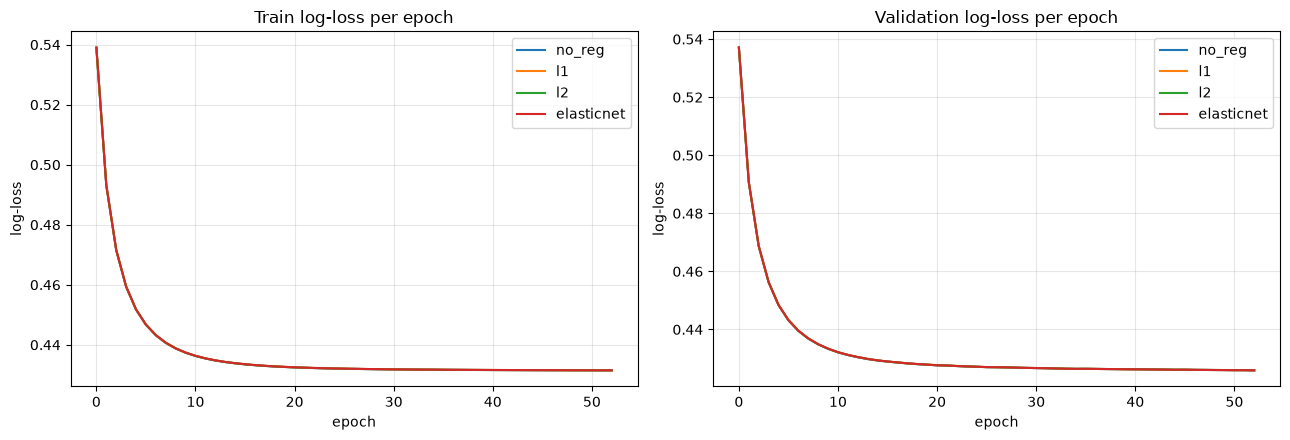

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, model in best_models.items():
    axes[0].plot(model.history['train'], label=name)
    axes[1].plot(model.history['val'], label=name)
axes[0].set_title('Train log-loss per epoch')
axes[1].set_title('Validation log-loss per epoch')
for ax in axes:
    ax.set_xlabel('epoch')
    ax.set_ylabel('log-loss')
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

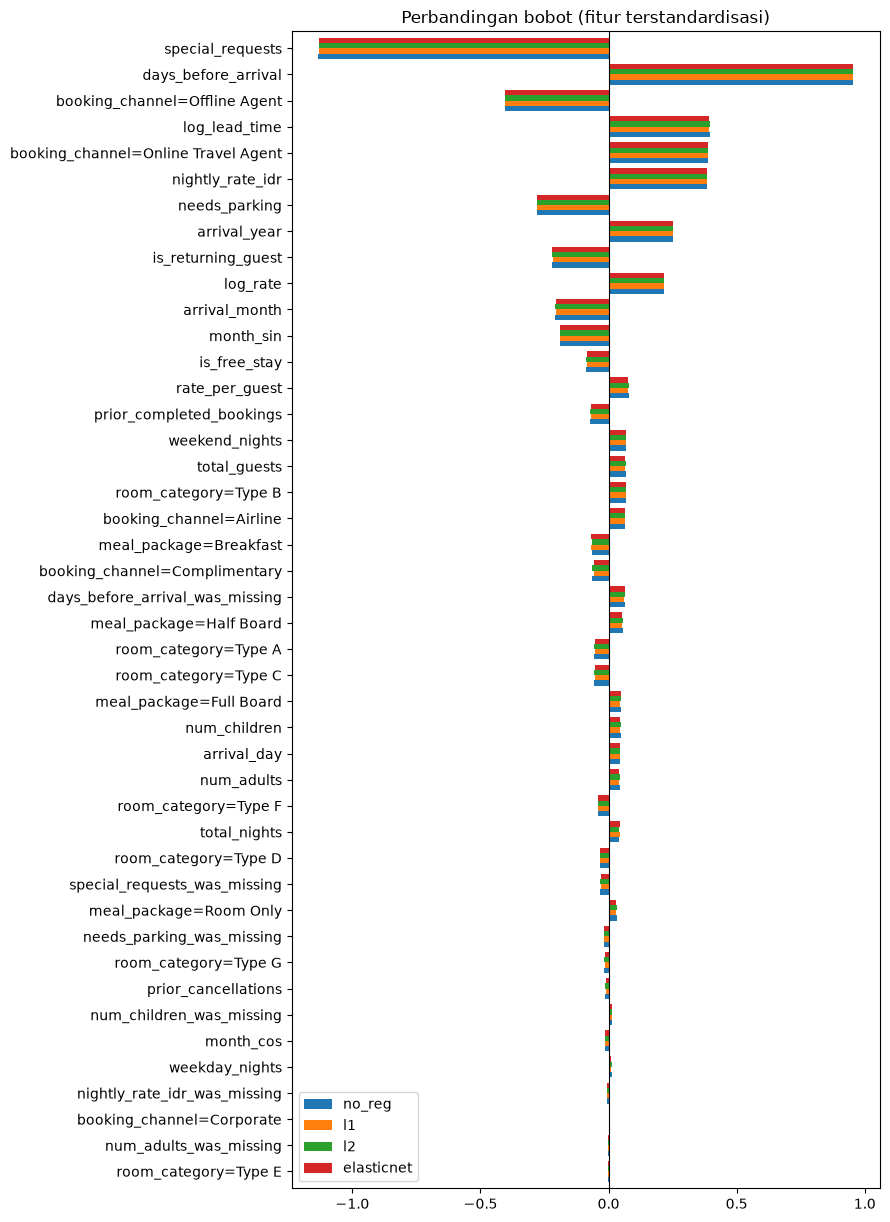

Fitur yang dinolkan oleh L1: []


In [12]:
coef_df = pd.DataFrame({name: m.w for name, m in best_models.items()}, index=prep.feature_names)
order = coef_df['no_reg'].abs().sort_values().index

ax = coef_df.loc[order].plot.barh(figsize=(9, max(6, 0.28 * len(order))), width=0.8)
ax.set_title('Perbandingan bobot (fitur terstandardisasi)')
ax.axvline(0, color='black', lw=0.8)
plt.tight_layout()
plt.show()

print('Fitur yang dinolkan oleh L1:', coef_df.index[coef_df['l1'].abs() < 1e-8].tolist())

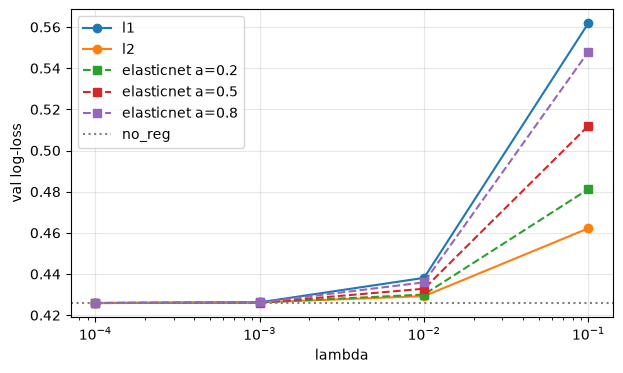

In [13]:
# efek lambda terhadap val log-loss
fig, ax = plt.subplots(figsize=(7, 4))
for name in ['l1', 'l2']:
    d = tuning_df[tuning_df['model'] == name].sort_values('lam')
    ax.plot(d['lam'], d['val_log_loss'], marker='o', label=name)
for r in L1_RATIOS:
    d = tuning_df[(tuning_df['model'] == 'elasticnet') & (tuning_df['l1_ratio'] == r)].sort_values('lam')
    ax.plot(d['lam'], d['val_log_loss'], marker='s', ls='--', label=f'elasticnet a={r}')
ax.axhline(log_uniconilear['no_reg'], color='gray', ls=':', label='no_reg')
ax.set_xscale('log')
ax.set_xlabel('lambda')
ax.set_ylabel('val log-loss')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 8. Model Final & Submission (metrik: F1-score)

Penilaian memakai **F1-score**. Untuk tiap model terbaik (no_reg, L1, L2, Elastic Net), threshold keputusan di-tuning di data validasi agar F1 maksimal. Model dengan F1 validasi tertinggi dipilih, dilatih ulang pada seluruh data train, lalu dipakai untuk memprediksi test.

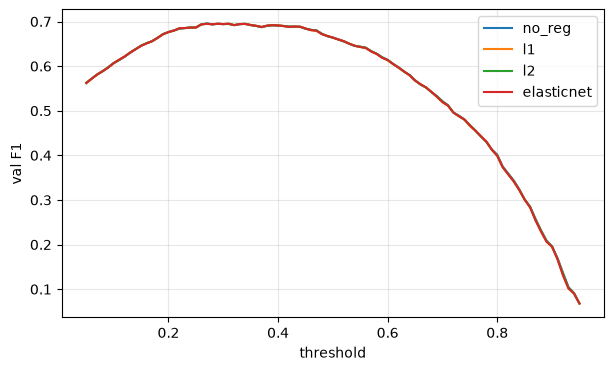

Model terbaik: no_reg {'penalty': None} | threshold = 0.27 | val F1 = 0.6956


,best_threshold,val_f1@0.5,val_f1@best,val_log_loss
model,,,,
no_reg,0.27,0.664044,0.695571,0.425910
l2,0.27,0.664044,0.695409,0.425927
l1,0.29,0.663639,0.695151,0.425908
elasticnet,0.31,0.663840,0.695074,0.425912


In [14]:
THRESHOLD_METRIC = 'f1'
thresholds = np.arange(0.05, 0.951, 0.01)

plt.figure(figsize=(7, 4))
thr_rows = []
for name, model in best_models.items():
    p_va = model.predict_proba(X_va)
    scores = [classification_metrics(y_va, (p_va >= t).astype(int))[THRESHOLD_METRIC] for t in thresholds]
    i = int(np.argmax(scores))
    thr_rows.append({
        'model': name,
        'best_threshold': float(thresholds[i]),
        'val_f1@0.5': classification_metrics(y_va, model.predict(X_va))['f1'],
        'val_f1@best': scores[i],
        'val_log_loss': log_uniconilear[name],
    })
    plt.plot(thresholds, scores, label=name)
plt.xlabel('threshold')
plt.ylabel('val F1')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

thr_df = pd.DataFrame(thr_rows).set_index('model').sort_values('val_f1@best', ascending=False)
best_name = thr_df.index[0]
best_t = float(thr_df.loc[best_name, 'best_threshold'])
best_f1 = thr_df.loc[best_name, 'val_f1@best']
print(f'Model terbaik: {best_name} {best_params[best_name]} | threshold = {best_t:.2f} | val F1 = {best_f1:.4f}')
thr_df

In [15]:
prep_full = Preprocessor().fit(train)
X_full = prep_full.transform(train)
X_test = prep_full.transform(test)

n_epochs_final = len(best_models[best_name].history['train'])
final_model = LogisticRegressionScratch(**best_params[best_name], n_epochs=n_epochs_final).fit(X_full, y_all)

test_pred = final_model.predict(X_test, threshold=best_t)
submission = pd.DataFrame({'id': test['id'], TARGET: test_pred.astype(int)})
submission.to_csv(f'{OUTPUT_DIR}/submission_logreg.csv', index=False)

print(submission.shape)
print(submission[TARGET].value_counts(normalize=True))
submission.head()

(6844, 2)
is_canceled
0    0.545003
1    0.454997
Name: proportion, dtype: float64


,id,is_canceled
0,5cb6f473,1
1,c06b4ab3,1
2,22bf3fc3,1
3,25408a48,0
4,621586b6,0


## 9. Saving & Loading Model

Satu file `.pkl` berisi seluruh pipeline: **state preprocessor** (median, modus, kategori, mean/std), **state model** (bobot `w`, bias `b`, hyperparameter, history), **threshold** F1 terbaik, dan metadata. Yang disimpan adalah atribut objek (bukan kode), sehingga saat load objek dibangun ulang dari class `Preprocessor` dan `LogisticRegressionScratch` yang sudah didefinisikan di atas.

| File | Isi |
|---|---|
| `../models/logistic_regression_v3.pkl` | Model final (dilatih di seluruh train), dipakai untuk submission |
| `../models/logistic_regression_{no_reg,l1,l2,elasticnet}_v3.pkl` | Model terbaik tiap regularisasi (dilatih di split train) |

Contoh pemakaian setelah kernel di-restart (cukup jalankan sel definisi class dulu):

```python
prep_l, model_l, thr_l, meta = load_pipeline('../models/logistic_regression_v3.pkl')
pred = model_l.predict(prep_l.transform(test), threshold=thr_l)
# atau langsung: pred = predict_from_file('../models/logistic_regression_v3.pkl', test)
```

> Catatan: `pickle.load` dapat mengeksekusi kode, jadi hanya load file `.pkl` dari sumber yang dipercaya.

In [16]:
import pickle
from pathlib import Path

MODEL_DIR = Path('../models')
MODEL_DIR.mkdir(exist_ok=True)


def save_pipeline(path, preprocessor, model, threshold=0.5, meta=None):
    # simpan state (atribut) preprocessor + model + threshold dalam satu file .pkl
    bundle = {
        'format_version': 3,
        'preprocessor_state': dict(vars(preprocessor)),
        'model_state': dict(vars(model)),
        'threshold': float(threshold),
        'meta': meta or {},
    }
    with open(path, 'wb') as f:
        pickle.dump(bundle, f, protocol=pickle.HIGHEST_PROTOCOL)
    return Path(path)


def load_pipeline(path):
    # bangun ulang objek Preprocessor & LogisticRegressionScratch dari state yang tersimpan
    with open(path, 'rb') as f:
        bundle = pickle.load(f)
    preprocessor = Preprocessor.__new__(Preprocessor)
    preprocessor.__dict__.update(bundle['preprocessor_state'])
    model = LogisticRegressionScratch.__new__(LogisticRegressionScratch)
    model.__dict__.update(bundle['model_state'])
    return preprocessor, model, bundle['threshold'], bundle['meta']


def predict_from_file(path, df):
    preprocessor, model, threshold, _ = load_pipeline(path)
    return model.predict(preprocessor.transform(df), threshold=threshold)


# 1) model final (dilatih di seluruh train) -> dipakai untuk submission
final_path = save_pipeline(
    MODEL_DIR / 'logistic_regression_v3.pkl', prep_full, final_model, best_t,
    meta={'model': best_name, 'params': best_params[best_name], 'val_f1': float(best_f1)},
)

# 2) model terbaik tiap regularisasi (dilatih di split train) -> untuk perbandingan
for name, m in best_models.items():
    save_pipeline(
        MODEL_DIR / f'logistic_regression_{name}_v3.pkl', prep, m, thr_df.loc[name, 'best_threshold'],
        meta={'model': name, 'params': best_params[name], 'val_log_loss': float(log_uniconilear[name])},
    )

for p in sorted(MODEL_DIR.glob('*_v3.pkl')):
    print(f'{p.as_posix():<50} {p.stat().st_size / 1024:6.1f} KB')

../models/logistic_regression_elasticnet_v3.pkl       7.6 KB
../models/logistic_regression_l1_v3.pkl               7.6 KB
../models/logistic_regression_l2_v3.pkl               7.6 KB
../models/logistic_regression_no_reg_v3.pkl           7.1 KB
../models/logistic_regression_v3.pkl                  6.1 KB


In [17]:
# ---- load & verifikasi: hasil model yang di-load harus identik dengan model aslinya ----
prep_l, model_l, thr_l, meta_l = load_pipeline(final_path)
print('Loaded:', final_path.as_posix(), '|', meta_l, '| threshold =', thr_l)

pred_loaded = model_l.predict(prep_l.transform(test), threshold=thr_l)
assert np.array_equal(pred_loaded, test_pred), 'prediksi test berbeda!'
assert np.allclose(model_l.w, final_model.w) and model_l.b == final_model.b
print('Prediksi test dari model ter-load identik dengan model asli:', len(pred_loaded), 'baris')

rows = []
for name in best_models:
    p_, m_, t_, meta_ = load_pipeline(MODEL_DIR / f'logistic_regression_{name}_v3.pkl')
    Xv = p_.transform(val_part)
    rows.append({
        'model': name,
        'val_log_loss (loaded)': log_loss(y_va, m_.predict_proba(Xv)),
        'log_uniconilear': log_uniconilear[name],
        'val_f1 (loaded, threshold)': classification_metrics(y_va, m_.predict(Xv, threshold=t_))['f1'],
    })
pd.DataFrame(rows).set_index('model')

Loaded: ../models/logistic_regression_v3.pkl | {'model': 'no_reg', 'params': {'penalty': None}, 'val_f1': 0.6955710955710956} | threshold = 0.27
Prediksi test dari model ter-load identik dengan model asli: 6844 baris


,val_log_loss (loaded),log_uniconilear,"val_f1 (loaded, threshold)"
model,,,
no_reg,0.425910,0.425910,0.695571
l1,0.425908,0.425908,0.695151
l2,0.425927,0.425927,0.695409
elasticnet,0.425912,0.425912,0.695074


## 10. Video: Kontur Log-Loss & Lintasan Parameter (θ₀, θ₁)

Supaya fungsi loss bisa digambar sebagai kontur 2D, model diperkecil menjadi **2 parameter**:

$$p = \sigma(\theta_0 + \theta_1 x), \quad x = \texttt{log\_lead\_time}\ (\text{terstandardisasi})$$

Model dilatih dengan *full-batch gradient descent* dari titik awal yang sama untuk 4 varian. Kontur yang digambar adalah fungsi objektif $J(\theta_0,\theta_1)$ = log-loss + penalti; untuk *no_reg* kontur ini persis log-loss. Penalti hanya dikenakan pada θ₁ (bias tidak diregularisasi), sehingga regularisasi menarik minimum ke arah θ₁ = 0. Agar efek ini terlihat, λ visualisasi sengaja dibuat lebih besar daripada λ hasil tuning.

In [18]:
import matplotlib.animation as animation
from IPython.display import Video, display

try:  # ffmpeg dari paket imageio-ffmpeg; jika tidak ada, pakai ffmpeg sistem
    import imageio_ffmpeg
    plt.rcParams['animation.ffmpeg_path'] = imageio_ffmpeg.get_ffmpeg_exe()
except ImportError:
    pass

# ---- model 2 parameter: p = sigmoid(theta0 + theta1 * x) ----
FEAT = 'log_lead_time'
x1 = X_tr[:, prep.feature_names.index(FEAT)]
y1 = y_tr

VIS_LAMBDA = 0.1      # sengaja dibesarkan agar efek regularisasi terlihat jelas di plot
VIS_RATIO = 0.5       # alpha untuk Elastic Net
LR_VIS = 0.5
N_STEPS = 120
THETA_INIT = np.array([2.0, -2.5])
VIDEO_PATH = f'{OUTPUT_DIR}/loss_contour_trajectory.mp4'

variants = {
    'Tanpa regularisasi': (0.0, 0.0),
    f'L1 (λ={VIS_LAMBDA})': (VIS_LAMBDA, 0.0),
    f'L2 (λ={VIS_LAMBDA})': (0.0, VIS_LAMBDA),
    f'Elastic Net (λ={VIS_LAMBDA}, α={VIS_RATIO})': (VIS_LAMBDA * VIS_RATIO, VIS_LAMBDA * (1 - VIS_RATIO)),
}


def logloss_2p(t0, t1):
    z = t0 + t1 * x1
    return np.mean(np.logaddexp(0, z) - y1 * z)   # bentuk stabil dari log-loss


def gd_path(l1, l2):
    th = THETA_INIT.astype(float).copy()
    path = [th.copy()]
    for _ in range(N_STEPS):
        err = sigmoid(th[0] + th[1] * x1) - y1
        g0 = err.mean()
        g1 = (err * x1).mean() + l2 * th[1]
        th[0] -= LR_VIS * g0
        th[1] -= LR_VIS * g1
        if l1 > 0:  # proximal step L1 (bias tidak diregularisasi)
            th[1] = np.sign(th[1]) * max(abs(th[1]) - LR_VIS * l1, 0.0)
        path.append(th.copy())
    return np.array(path)


paths = {name: gd_path(*s) for name, s in variants.items()}

# ---- grid untuk kontur: log-loss murni, penalti hanya bergantung pada theta1 ----
allp = np.vstack(list(paths.values()))
t0_grid = np.linspace(allp[:, 0].min() - 0.8, allp[:, 0].max() + 0.8, 140)
t1_grid = np.linspace(allp[:, 1].min() - 0.8, allp[:, 1].max() + 0.8, 140)
base = np.empty((len(t1_grid), len(t0_grid)))
for r, b1 in enumerate(t1_grid):
    Z = t0_grid[:, None] + b1 * x1[None, :]
    base[r] = np.mean(np.logaddexp(0, Z) - y1[None, :] * Z, axis=1)
T0, T1 = np.meshgrid(t0_grid, t1_grid)

# ---- animasi ----
fig, axes = plt.subplots(2, 2, figsize=(12, 10.5))
artists = []
for ax, (name, (l1, l2)) in zip(axes.ravel(), variants.items()):
    J = base + l1 * np.abs(T1) + 0.5 * l2 * T1 ** 2
    levels = np.geomspace(J.min() * 1.002, J.max(), 25)
    ax.contourf(T0, T1, J, levels=levels, cmap='viridis', alpha=0.85)
    cs = ax.contour(T0, T1, J, levels=levels[::3], colors='white', linewidths=0.6)
    ax.clabel(cs, fmt='%.2f', fontsize=7)
    r, c = np.unravel_index(np.argmin(J), J.shape)
    ax.plot(t0_grid[c], t1_grid[r], marker='*', ms=16, color='gold', mec='black', label='minimum objektif')
    ax.plot(*THETA_INIT, 'o', color='white', mec='black', ms=7, label='titik awal')
    line, = ax.plot([], [], '-', color='red', lw=2, label='lintasan GD')
    point, = ax.plot([], [], 'o', color='red', mec='black', ms=8)
    ax.set_xlabel('θ₀ (bias)')
    ax.set_ylabel(f'θ₁ (bobot {FEAT})')
    ax.legend(loc='upper right', fontsize=8)
    artists.append((ax, name, paths[name], line, point, l1, l2))

frames = list(range(N_STEPS + 1)) + [N_STEPS] * 25   # tahan frame terakhir


def update(k):
    out = []
    for ax, name, path, line, point, l1, l2 in artists:
        line.set_data(path[:k + 1, 0], path[:k + 1, 1])
        point.set_data([path[k, 0]], [path[k, 1]])
        t0, t1 = path[k]
        ll = logloss_2p(t0, t1)
        ax.set_title(f'{name}\nθ=({t0:.3f}, {t1:.3f})  log-loss={ll:.4f}  J={ll + l1 * abs(t1) + 0.5 * l2 * t1 ** 2:.4f}', fontsize=10)
        out += [line, point]
    fig.suptitle(f'Kontur log-loss & lintasan (θ₀, θ₁) — iterasi {k}/{N_STEPS}', fontsize=14)
    return out


update(0)                                  # isi judul dulu agar tight_layout memberi ruang
fig.tight_layout(rect=[0, 0, 1, 0.97], h_pad=2.5)
ani = animation.FuncAnimation(fig, update, frames=frames, blit=False)
ani.save(VIDEO_PATH, writer=animation.FFMpegWriter(fps=12, bitrate=3000), dpi=110)
plt.close(fig)

for name, path in paths.items():
    print(f'{name:<38} theta akhir = ({path[-1, 0]:.4f}, {path[-1, 1]:.4f})')
print('Video disimpan di', VIDEO_PATH)
display(Video(VIDEO_PATH, embed=True, width=900))

Tanpa regularisasi                     theta akhir = (-0.9326, 1.1078)
L1 (λ=0.1)                             theta akhir = (-0.7427, 0.3608)
L2 (λ=0.1)                             theta akhir = (-0.7862, 0.6033)
Elastic Net (λ=0.1, α=0.5)             theta akhir = (-0.7662, 0.5059)
Video disimpan di ../output/loss_contour_trajectory.mp4
